# XGBoost tuneado para el pronóstico de dengue en Lima (t+4)

Modelo propio de Luis Leiva. Compara, con **la misma prueba que el LSTM/GRU** (`02_modelos.ipynb`: las 759 semanas evaluables de Lima, horizonte 4):

1. **Persistencia** (baseline): predice que dentro de 4 semanas habrá los mismos casos que hoy.
2. **XGBoost tuneado**: variables climáticas rezagadas, historial de casos y estacionalidad.
3. **XGBoost tuneado + regional + variables nuevas**: añade casos de otros departamentos y variables dinámicas.

El modelo predice el cambio `delta = log1p(casos t+4) − log1p(casos t)`, no el nivel. Se reentrena cada 13 semanas (walk-forward) solo con filas cuyo objetivo ya se conocía. Todo el código vive en `src/` (`preprocessing.py`, `models.py`, `evaluation.py`). Ejecutar desde `notebooks/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, "../src")

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from evaluation import PERCENTIL_BROTE, a_casos, ic_bootstrap, metricas, prueba_lima
from models import SEMILLAS, build_baseline, buscar, walk_forward
from preprocessing import (AMPLIADO, DEPARTAMENTOS_MODELO, FEATURES, NUEVAS, PROCESSED,
                           REG, generar_ampliado, preparar)

RESULTS = Path("../results")
CACHE = RESULTS / "tuning_hiperparametros.json"


## 1. Datos y conjunto de prueba

Universo de entrenamiento: Lima, Ica, La Libertad, Ancash y Callao. La prueba son las semanas de Lima con ventana de 8 semanas y horizonte 4 (el mismo conjunto que usa el LSTM). `preparar()` añade las variables regionales (`REG`, promedio/crecimiento/máximo de los otros departamentos) y las nuevas (`NUEVAS`), todas calculables en la semana t.

In [2]:
ref = prueba_lima(pd.read_csv(PROCESSED / "modelado.csv", parse_dates=["fecha_inicio"]))
m = preparar(DEPARTAMENTOS_MODELO)
lima = m[m.departamento == "LIMA"]
test_idx = lima.index[lima.fecha_inicio.isin(ref.fecha_inicio)]
prueba = m.loc[test_idx].reset_index(drop=True)
real_log = prueba["objetivo"].to_numpy()
fechas = pd.DatetimeIndex(prueba["fecha_inicio"])
umbral = np.percentile(a_casos(real_log), PERCENTIL_BROTE)
print(f"Filas de entrenamiento posibles: {len(m)} | prueba Lima: {len(prueba)} semanas "
      f"({fechas.min().date()} a {fechas.max().date()})")
print(f"Semana de brote = casos >= {umbral:.0f} (percentil {PERCENTIL_BROTE})")
print(f"Variables base: {len(FEATURES)} | regionales: {REG} | nuevas: {NUEVAS}")

Filas de entrenamiento posibles: 3850 | prueba Lima: 759 semanas (2010-04-18 a 2024-10-27)
Semana de brote = casos >= 55 (percentil 90)
Variables base: 35 | regionales: ['reg_log', 'reg_crec', 'reg_max'] | nuevas: ['acum13', 'acum52', 'acel', 'anom52', 'reg_lag2', 'reg_crec1', 'temp_anom']


## 2. Hiperparámetros (fine-tuning)

Búsqueda aleatoria (30 configuraciones) con validación cruzada temporal de ventana creciente. Los años de validación son 2016, 2017, 2020, 2021, 2022 (y 2023 para el segundo corte). El puntaje es el MAE relativo a la persistencia, promediado entre años. Hay dos cortes para no usar el futuro: el de 2022 sirve para predecir 2023 y el de 2023 para predecir 2024. Se usa el resultado guardado en `results/tuning_hiperparametros.json`; si no existe, se vuelve a buscar (~10 min).

In [3]:
if CACHE.exists():
    mejores = json.loads(CACHE.read_text())
else:
    mejores, tabla_cv = buscar(m)
    CACHE.write_text(json.dumps(mejores, indent=2))
    tabla_cv.to_csv(RESULTS / "tuning_cv.csv", index=False)
for corte, r in mejores.items():
    x = r["XGBoost"]
    print(f"Corte {corte}: CV relativo a persistencia {x['cv_defecto']:.3f} (defecto) -> {x['cv']:.3f}")
    print("   ", x["params"])

Corte 2022: CV relativo a persistencia 0.825 (defecto) -> 0.730
    {'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 10, 'reg_lambda': 1}
Corte 2023: CV relativo a persistencia 0.817 (defecto) -> 0.739
    {'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.6, 'colsample_bytree': 0.8, 'min_child_weight': 20, 'reg_lambda': 1}


## 3. Prueba walk-forward en Lima

Tres semillas (42-44), `N_JOBS=1`. Ojo: XGBoost no da el mismo resultado con distinto número de hilos, así que las comparaciones deben hacerse con el mismo `N_JOBS`.

In [4]:
variantes = {"XGBoost tuneado": FEATURES,
             "XGBoost tuneado + regional + nuevas": FEATURES + REG + NUEVAS}
persistencia = prueba["log_casos"].to_numpy()
preds = {"Persistencia": [persistencia]}
filas = []
for nombre, cols in variantes.items():
    preds[nombre] = [walk_forward(m, test_idx, mejores, s, cols) for s in SEMILLAS]

def tabla(mask=None):
    mask = np.ones(len(prueba), bool) if mask is None else mask
    out = []
    for nombre, ps in preds.items():
        r = [metricas(real_log[mask], p[mask], fechas[mask], umbral) for p in ps]
        out.append({"modelo": nombre,
                    "MAE": np.mean([x["MAE"] for x in r]), "sd_MAE": np.std([x["MAE"] for x in r]),
                    "RMSE": np.mean([x["RMSE"] for x in r]), "WAPE %": np.mean([x["WAPE"] for x in r]),
                    "MAE brote": np.mean([x["MAE_brote"] for x in r]),
                    "Error pico": np.mean([x["Error_pico"] for x in r])})
    return pd.DataFrame(out).set_index("modelo")

print("Todo el periodo (759 semanas), media de", len(SEMILLAS), "semillas:")
print(tabla().round(1).to_string())
print("\nSolo 2023-2024 (olas grandes):")
print(tabla((fechas >= "2023-01-01")).round(1).to_string())

Todo el periodo (759 semanas), media de 3 semillas:
                                       MAE  sd_MAE   RMSE  WAPE %  MAE brote  Error pico
modelo                                                                                  
Persistencia                         132.8     0.0  663.6    82.6     1266.1     -4965.0
XGBoost tuneado                       79.1     3.5  463.6    49.2      757.0     -4460.1
XGBoost tuneado + regional + nuevas   67.0     1.6  371.2    41.7      638.3     -5231.6

Solo 2023-2024 (olas grandes):
                                        MAE  sd_MAE    RMSE  WAPE %  MAE brote  Error pico
modelo                                                                                    
Persistencia                         1014.5     0.0  1865.5    82.1     1719.8     -4965.0
XGBoost tuneado                       596.3    27.9  1303.1    48.3     1016.8     -4460.1
XGBoost tuneado + regional + nuevas   502.5    12.1  1043.1    40.7      855.4     -5231.6


## 4. ¿La mejora es real? Bootstrap por bloques

Diferencia de MAE contra la persistencia (negativa = el modelo es mejor), con IC 95 % por bootstrap de bloques de 8 semanas (respeta la autocorrelación) sobre la predicción promedio de las semillas.

In [5]:
real = a_casos(real_log)
pers = a_casos(persistencia)
for nombre in variantes:
    p = np.mean([a_casos(x) for x in preds[nombre]], axis=0)
    d, lo, hi, pm = ic_bootstrap(real, p, pers)
    print(f"{nombre:38s} dif. MAE {d:7.1f} casos  IC95 [{lo:6.1f}, {hi:6.1f}]  P(mejor que persistencia) = {pm:.2f}")

XGBoost tuneado                        dif. MAE   -55.2 casos  IC95 [-120.4,  -11.3]  P(mejor que persistencia) = 1.00
XGBoost tuneado + regional + nuevas    dif. MAE   -66.4 casos  IC95 [-141.3,  -13.8]  P(mejor que persistencia) = 1.00


## 5. Comparación con el LSTM/GRU de Alonso en 2024

La prueba de `02_modelos.ipynb` cubre solo los orígenes de 2024. Aquí se evalúa XGBoost sobre esos mismos orígenes y se comparan con los números que dio su notebook al ejecutarlo (LSTM/GRU regionales con historial y clima, una semilla; tomados de esa corrida, no recalculados aquí).

In [6]:
m24 = (fechas >= "2024-01-01")
filas = []
for nombre, ps in preds.items():
    p = np.mean([a_casos(x) for x in ps], axis=0)[m24]
    e = p - real[m24]
    filas.append((nombre, np.abs(e).mean(), np.sqrt((e**2).mean()), e.mean()))
filas += [("LSTM regional (Alonso, 02_modelos)", 1495.8, 2865.8, -1452.4),
          ("GRU regional (Alonso, 02_modelos)", 1678.2, 3192.7, -1669.1)]
t = pd.DataFrame(filas, columns=["modelo", "MAE", "RMSE", "sesgo"]).set_index("modelo")
print(f"Orígenes de 2024 comunes: {int(m24.sum())} | casos medios: {real[m24].mean():.0f}")
print(t.round(1).to_string())

Orígenes de 2024 comunes: 43 | casos medios: 2030
                                        MAE    RMSE   sesgo
modelo                                                     
Persistencia                         1688.2  2641.5    11.9
XGBoost tuneado                       968.6  1787.5   -35.4
XGBoost tuneado + regional + nuevas   793.4  1387.9  -168.6
LSTM regional (Alonso, 02_modelos)   1495.8  2865.8 -1452.4
GRU regional (Alonso, 02_modelos)    1678.2  3192.7 -1669.1


## 6. Otros departamentos

Con Lima hay pocas semanas de brote (92 % del error está en 30 semanas), así que se repite la prueba en los 8 departamentos con más casos en 2023-24 (≥ 15 000), regla fijada antes de ver resultados. El entrenamiento usa 18 departamentos y las mismas semillas e hiperparámetros. Métrica: MAE relativo a la persistencia (1 = igual, menor es mejor), semilla 42. Tarda unos minutos.

In [7]:
PRUEBA = ["LIMA", "PIURA", "LA LIBERTAD", "ICA", "LAMBAYEQUE", "ANCASH", "TUMBES", "SAN MARTIN"]
if not AMPLIADO.exists():
    generar_ampliado()
m18 = preparar()   # los 18 departamentos
t18 = m18.index[m18.departamento.isin(PRUEBA) & m18.fecha_inicio.isin(ref.fecha_inicio)]
pr = m18.loc[t18]
real18, pers18 = a_casos(pr["objetivo"].to_numpy()), a_casos(pr["log_casos"].to_numpy())
dep, ola = pr["departamento"].to_numpy(), (pr["fecha_inicio"] >= "2023-01-01").to_numpy()
rel = {}
for nombre, cols in {"XGBoost tuneado": FEATURES,
                     "XGBoost tuneado + regional + nuevas": FEATURES + REG + NUEVAS}.items():
    p = a_casos(walk_forward(m18, t18, mejores, 42, cols))
    rel[nombre] = {d: np.abs(real18 - p)[(dep == d) & ola].mean() / np.abs(real18 - pers18)[(dep == d) & ola].mean()
                   for d in PRUEBA}
r18 = pd.DataFrame(rel).T
r18["MEDIA"] = r18.mean(axis=1)
print("MAE relativo a la persistencia, 2023-2024:")
print(r18.round(2).to_string())

MAE relativo a la persistencia, 2023-2024:
                                     LIMA  PIURA  LA LIBERTAD   ICA  LAMBAYEQUE  ANCASH  TUMBES  SAN MARTIN  MEDIA
XGBoost tuneado                      0.56   0.55         0.74  0.60        0.65    0.86    0.94        1.08   0.75
XGBoost tuneado + regional + nuevas  0.54   0.55         0.77  0.64        0.58    0.83    0.96        0.90   0.72


## 7. Gráfico y archivos de resultados

Escrito: results/metrics.csv, results/predicciones_lima.csv, results/plots/xgboost_vs_real.png


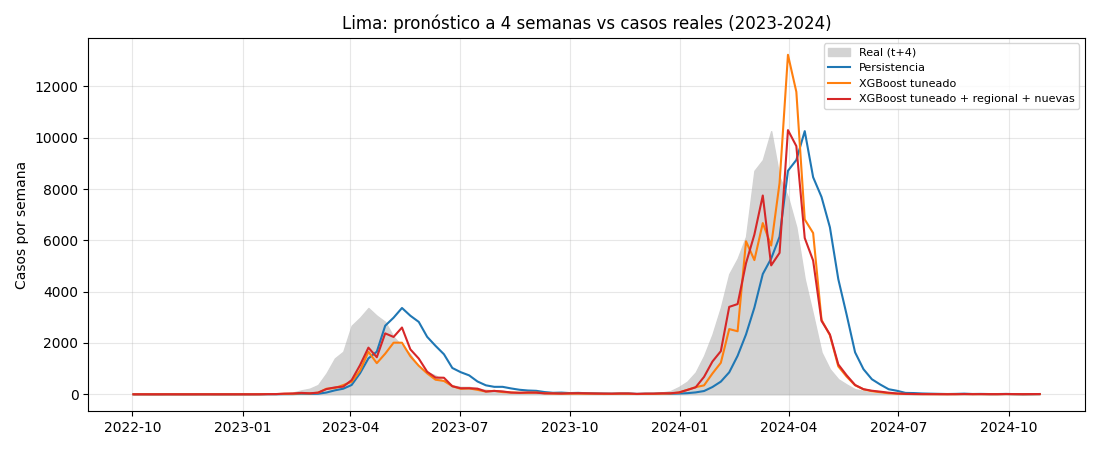

In [8]:
p_mean = {n: np.mean([a_casos(x) for x in ps], axis=0) for n, ps in preds.items()}
d = fechas >= "2022-10-01"
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(fechas[d], real[d], color="lightgray", label="Real (t+4)")
for nombre, color in [("Persistencia", "tab:blue"), ("XGBoost tuneado", "tab:orange"),
                      ("XGBoost tuneado + regional + nuevas", "tab:red")]:
    ax.plot(fechas[d], p_mean[nombre][d], lw=1.5, color=color, label=nombre)
ax.set(ylabel="Casos por semana", title="Lima: pronóstico a 4 semanas vs casos reales (2023-2024)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(RESULTS / "plots" / "xgboost_vs_real.png", dpi=150)
plt.show()

filas = []
for nombre, ps in preds.items():
    r = [metricas(real_log, p, fechas, umbral) for p in ps]
    filas += [(nombre, k, round(float(np.mean([x[k] for x in r])), 4)) for k in r[0]]
pd.DataFrame(filas, columns=["modelo", "metrica", "valor"]).to_csv(RESULTS / "metrics.csv", index=False)
sal = pd.DataFrame({"fecha_inicio": fechas, "real": real.round(2)})
for n, p in p_mean.items():
    sal[n] = p.round(2)
sal.to_csv(RESULTS / "predicciones_lima.csv", index=False)
print("Escrito: results/metrics.csv, results/predicciones_lima.csv, results/plots/xgboost_vs_real.png")